# DataHub — Galaxy Star Formation Rate Prediction
## Midterm + Final Scientific Report Template

This notebook is both your **analysis code** and your **scientific report**. Use the **same notebook for both submission stages**.

- **Part I — Midterm Report:** complete all required Part I sections and submit the notebook.
- **Part II — Final Report:** continue in the same notebook, preserve Part I, and complete the final analysis, code, results, and discussion.

## Participant Information

**Application ID**

**email:**

---
# Part I — Midterm Report

**Goal:** establish a scientifically motivated modeling plan. Part I should demonstrate that you understand the prediction problem, have inspected the data carefully, established a defensible validation procedure, and produced preliminary results.

### Part I deliverables
1. Problem & objective
2. Data loading and quality checks
3. Exploratory data analysis
4. Data preparation and feature engineering
5. Validation and evaluation strategy
6. Baseline results
7. Preliminary model / proposed method
8. Midterm summary and next-step plan

## 1. Problem & Objective — **STUDENT RESPONSE**

In approximately **150–250 words**, explain:
- what quantity you are predicting;
- what information is available as input;
- why this is a non-trivial regression problem;
- one or more astrophysical considerations that may affect the prediction.

**Response:**  
...

## 2. Setup, Reproducibility & Data Loading

The fixed cells below establish common imports, a random seed, and basic schema checks. You may change the data path if necessary, but do not silently alter the raw data.

In [1]:
# DO NOT MODIFY — core imports and seed
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
pd.set_option("display.max_columns", 100)
print("Random seed:", RANDOM_SEED)

Random seed: 42


In [2]:
# You may change DATA_PATH only if needed.
CANDIDATES = [
    Path("Galaxy Features with Position and Velocity for Star Formation Rate Prediction.csv"),
    Path("../../Galaxy Features with Position and Velocity for Star Formation Rate Prediction.csv"),  # 조장: 레포의 work/조장/에서 실행할 때
    Path("/mnt/data/Galaxy Features with Position and Velocity for Star Formation Rate Prediction.csv"),
]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found. Place the course CSV beside this notebook or update DATA_PATH.")

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())

Shape: (208437, 15)


,subhalo_id,log10_halo_mass,log10_stellar_mass,log10_BH_mass,log10_main_prog_mass,log10_main_prog_stellar_mass,log10_mass_ratio,log10_overdensity_plus_1,pos_x,pos_y,pos_z,vel_x,vel_y,vel_z,sfr_linear
0,0.0,14.807566,12.812004,10.443699,14.631294,12.589542,-3.239739,2.383863,21.290455,101.703239,118.123352,-287.557892,-62.394615,-30.580877,107.896912
1,1.0,13.870680,12.091579,8.625058,13.819390,11.916792,-6.000000,2.025288,20.735514,101.805397,120.937294,786.127563,258.246796,-680.667908,68.733315
2,2.0,13.672584,12.032370,9.829654,13.620131,11.864630,-6.000000,1.704644,18.711687,103.225121,120.417160,890.943054,-756.617004,-358.727631,0.232002
3,3.0,13.650022,12.019966,9.312719,13.577394,11.849984,-6.000000,1.833376,23.493862,102.198166,113.814438,-92.127396,532.597473,544.153687,12.698732
4,4.0,13.131606,11.563723,9.452775,13.026983,11.395634,-6.000000,1.830341,24.067015,101.780312,112.495789,-187.708572,-224.876968,978.109558,0.715540


In [3]:
# DO NOT MODIFY — schema checks
TARGET = "sfr_linear"
ID_COLUMN = "subhalo_id"
EXPECTED_COLUMNS = [
    "subhalo_id", "log10_halo_mass", "log10_stellar_mass", "log10_BH_mass",
    "log10_main_prog_mass", "log10_main_prog_stellar_mass", "log10_mass_ratio",
    "log10_overdensity_plus_1", "pos_x", "pos_y", "pos_z",
    "vel_x", "vel_y", "vel_z", "sfr_linear"
]
missing = sorted(set(EXPECTED_COLUMNS) - set(df.columns))
if missing:
    raise ValueError(f"Missing expected columns: {missing}")
n_missing_target = int(df[TARGET].isna().sum())
print(f"Missing target values: {n_missing_target}")
if n_missing_target > 0:
    print(f"Dropping {n_missing_target} row(s) with missing target before modeling.")
    df = df.dropna(subset=[TARGET]).copy()
print(f"Schema check passed. Samples available for modeling: {len(df):,}")


Missing target values: 0
Schema check passed. Samples available for modeling: 208,437


### 2.1 Data Quality Notes — **STUDENT RESPONSE**

Report the dataset size, missing values, duplicate handling (if any), and any other data-quality issue you found. Remember that **`sfr_linear = 0` is a valid physical target and is not the same as a missing value**.

**Response:**  
...

## 3. Exploratory Data Analysis (EDA) — **STUDENT WORK**

Your EDA should be selective and scientifically useful rather than a gallery of plots. Include **at least two analyses/figures that influence a later modeling decision**. At minimum, examine the target distribution and relevant relationships between predictors and SFR.

For every important figure/table, add a short interpretation directly below it: **What does it show? Why might the pattern occur? How does it affect your modeling choices?**

In [4]:
# STUDENT TODO — starter summary
print(df[TARGET].describe(percentiles=[0.5, 0.9, 0.99]))
zero_fraction = (df[TARGET] == 0).mean()
print(f"Exact zero-SFR fraction: {zero_fraction:.2%}")

# Add your EDA here.

count    208437.000000
mean          3.709985
std          11.794583
min           0.000000
50%           1.631928
90%           7.554342
99%          34.859419
max        2145.372800
Name: sfr_linear, dtype: float64
Exact zero-SFR fraction: 8.66%


### 3.1 EDA Findings — **STUDENT RESPONSE**

**Finding 1:** ...  
**Finding 2:** ...  
**Additional finding(s):** ...  

**Modeling decisions motivated by the EDA:** ...

## 4. Data Preparation & Feature Engineering — **STUDENT WORK**

Document all choices that affect model inputs. Discuss feature inclusion/exclusion, missing-value treatment, transformations, scaling, and engineered features where applicable. **`subhalo_id` must not be used as a predictive feature.**

In [5]:
# Default allowed feature set. You may modify FINAL_FEATURES, but never include subhalo_id or sfr_linear.
ALLOWED_FEATURES = [c for c in df.columns if c not in [ID_COLUMN, TARGET]]
FINAL_FEATURES = ALLOWED_FEATURES.copy()

assert ID_COLUMN not in FINAL_FEATURES
assert TARGET not in FINAL_FEATURES
assert set(FINAL_FEATURES).issubset(set(ALLOWED_FEATURES))

X = df[FINAL_FEATURES].copy()
y = df[TARGET].copy()
print(f"Using {len(FINAL_FEATURES)} features:")
print(FINAL_FEATURES)

# STUDENT TODO: add preprocessing / feature engineering if desired.

Using 13 features:
['log10_halo_mass', 'log10_stellar_mass', 'log10_BH_mass', 'log10_main_prog_mass', 'log10_main_prog_stellar_mass', 'log10_mass_ratio', 'log10_overdensity_plus_1', 'pos_x', 'pos_y', 'pos_z', 'vel_x', 'vel_y', 'vel_z']


### 4.1 Preprocessing Rationale — **STUDENT RESPONSE**

| Choice | What you did | Why |
|---|---|---|
| Feature selection |  |  |
| Missing values |  |  |
| Scaling / transformation |  |  |
| Feature engineering |  |  |

**Additional explanation:** ...

## 5. Validation & Evaluation Strategy

A common reference split is provided for comparability. If you use cross-validation or another additional strategy, describe it clearly and prevent data leakage.

> **조장(ZizonK7) 작업 노트북 — 머신러닝 담당 절: 5.1 검증 전략, 6.1 기준선 해석, 7·7.1 예비 모델**
>
> - 템플릿 원본을 그대로 복사하고 5~7절에만 칸을 더했다. `DO NOT MODIFY` 칸은 손대지 않았다. 1~4절·8절은 템플릿 그대로다(EDA는 `../팀원/james_eda.ipynb`, 1·8절은 월요일에 같이 쓴다).
> - 실행: 데이터 CSV를 이 노트북과 같은 폴더에 두거나 2절 `CANDIDATES`에 경로를 더한 뒤 위에서부터 끝까지 실행. CPU 4코어에서 약 1분.
> - 원칙: **고르기는 `X_train` 안 5-fold CV, 보고는 공통 분할 val**. 모든 비교 모델은 기준선과 같은 HGB 설정(학습률 0.08, 잎 31, `max_iter` 150, seed 42)을 써서 손실·구조만 바뀌게 했다.
> - Part II(9절 이후)는 템플릿 그대로라 9.2 칸이 `FINAL_MODEL`을 기준선 복사본으로 덮어쓴다. 그래서 10절 "Final model" 줄과 15절 `RESULTS`는 지금 기준선 숫자다. 제출용 노트북에서는 7절의 `TwoStageSFR`가 그대로 이어지게 합친다.

In [6]:
# DO NOT MODIFY — common reference split
# Stratify by zero vs positive SFR so both regimes are represented consistently.
regime = (y > 0).astype(int)
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=regime,
)
print("Train:", X_train.shape, "Validation:", X_val.shape)
print("Validation zero-SFR fraction:", f"{(y_val == 0).mean():.2%}")

Train: (166749, 13) Validation: (41688, 13)
Validation zero-SFR fraction: 8.66%


In [7]:
# DO NOT MODIFY — standardized metrics
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred),
    }

def evaluate_sfr(y_true, y_pred, label="Model"):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    rows = []
    masks = {
        "All": np.ones(len(y_true), dtype=bool),
        "SFR = 0": y_true == 0,
        "SFR > 0": y_true > 0,
        "Top 10% SFR": y_true >= np.quantile(y_true, 0.90),
    }
    for regime_name, mask in masks.items():
        if mask.sum() == 0:
            continue
        m = regression_metrics(y_true[mask], y_pred[mask])
        rows.append({"Model": label, "Regime": regime_name, "N": int(mask.sum()), **m})
    return pd.DataFrame(rows)

#### 5절 보조 — `X_train` 안 5-fold CV (검증 데이터는 쓰지 않는다)

In [8]:
# 5절 보조 (조장): 하이퍼파라미터는 X_train 안 5-fold CV로만 비교한다. 공통 분할의 X_val/y_val은 쓰지 않는다.
from sklearn.model_selection import KFold

def rmse(a, b):
    return mean_squared_error(a, b) ** 0.5

HGB = dict(learning_rate=0.08, max_iter=150, max_leaf_nodes=31, random_state=RANDOM_SEED)  # 기준선과 같은 설정

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
Xtr = X_train.reset_index(drop=True)
ytr = y_train.reset_index(drop=True)
FOLDS = list(kf.split(Xtr))
print("fold별 최대 SFR:", [round(float(ytr.iloc[te].max())) for _, te in FOLDS])
print("fold별 SFR > 100 개수:", [int((ytr.iloc[te] > 100).sum()) for _, te in FOLDS])

grid = [(0.08, 150, 31), (0.08, 500, 31), (0.02, 150, 31), (0.3, 150, 31), (0.08, 150, 7), (0.08, 150, 3)]
cv_rows = []
for lr, it, lv in grid:
    fold_rmse, fold_rmse_le100, n_iters = [], [], []
    for tr, te in FOLDS:
        m = HistGradientBoostingRegressor(learning_rate=lr, max_iter=it, max_leaf_nodes=lv,
                                          random_state=RANDOM_SEED).fit(Xtr.iloc[tr], ytr.iloc[tr])
        p, yt = m.predict(Xtr.iloc[te]), ytr.iloc[te].to_numpy()
        fold_rmse.append(rmse(yt, p))
        fold_rmse_le100.append(rmse(yt[yt <= 100], p[yt <= 100]))
        n_iters.append(m.n_iter_)
    cv_rows.append({"learning_rate": lr, "max_iter": it, "max_leaf_nodes": lv,
                    "CV RMSE": np.mean(fold_rmse), "fold SD": np.std(fold_rmse, ddof=1),
                    "fold RMSE": [round(f, 2) for f in fold_rmse],
                    "CV RMSE (SFR<=100)": np.mean(fold_rmse_le100),
                    "n_iter_ (fold별)": n_iters})
cv_table = pd.DataFrame(cv_rows)
display(cv_table.round(3))

fold별 최대 SFR: [2145, 1414, 564, 463, 334]
fold별 SFR > 100 개수: [58, 49, 31, 36, 35]


,learning_rate,max_iter,max_leaf_nodes,CV RMSE,fold SD,fold RMSE,CV RMSE (SFR<=100),n_iter_ (fold별)
0,0.08,150,31,8.325,3.988,"[14.44, 10.32, 6.01, 5.4, 5.45]",4.075,"[84, 35, 41, 47, 30]"
1,0.08,500,31,8.325,3.988,"[14.44, 10.32, 6.01, 5.4, 5.45]",4.075,"[84, 35, 41, 47, 30]"
2,0.02,150,31,8.321,4.006,"[14.48, 10.32, 5.97, 5.48, 5.37]",3.849,"[150, 149, 123, 121, 106]"
3,0.30,150,31,8.660,3.866,"[14.53, 10.65, 6.72, 5.61, 5.79]",4.671,"[29, 17, 21, 13, 14]"
4,0.08,150,7,8.427,3.968,"[14.41, 10.61, 6.05, 5.6, 5.46]",3.992,"[104, 45, 49, 59, 69]"
5,0.08,150,3,8.512,3.960,"[14.46, 10.73, 6.21, 5.6, 5.56]",3.985,"[150, 147, 91, 131, 105]"


**무엇을 보여 주나.** 6개 설정의 CV RMSE는 학습률 0.3(8.660)만 뚜렷이 나쁘고 나머지는 8.321~8.512로 0.2 안에 모인다. 반면 같은 설정 안에서 fold RMSE는 5.4~14.4로 흔들린다(fold SD 약 4.0).

**왜.** fold RMSE 순서가 "fold별 최대 SFR" 순서(2145, 1414, 564, 463, 334)와 같다. 어느 fold에 가장 큰 은하 몇 개가 들어갔는지가 RMSE를 정한다. SFR ≤ 100만 재면 설정별 CV 평균이 3.8~4.7로 내려간다. 즉 흔들림은 설정 차이가 아니라 꼬리와 지표 때문이다. `max_iter` 500이 150과 똑같은 것은 early stopping이 fold마다 30~84번째 트리에서 멈춰 상한에 닿지 않기 때문이다.

**모델에 주는 결정.** 설정 간 차이(≤ 0.2)가 fold SD(약 4)보다 훨씬 작아 CV로 하이퍼파라미터를 가를 수 없다. 그래서 7절의 모든 모델은 **기준선 설정을 그대로** 쓰고(변인 통제), 손실과 구조만 바꿔 비교한다.

### 5.1 Validation Rationale — **STUDENT RESPONSE**

**Response:**

- **분리.** 템플릿의 공통 분할(train 80% 166,749개 / val 20% 41,688개, SFR = 0 여부로 층화, seed 42)을 그대로 쓴다. 두 regime의 비율은 train·val 모두 8.66%다. **val은 최종 비교와 보고에만** 쓴다. 하이퍼파라미터와 모델 구조를 고를 때는 `X_train` 안의 5-fold CV(`KFold`, shuffle, seed 42)를 쓴다. HGB의 early stopping은 학습 데이터 안의 10%를 내부 검증으로 쓰므로 val을 보지 않는다.
- **지표.** 공식 지표인 val **All RMSE**로 판정한다. 하지만 RMSE 한 숫자는 사실상 꼬리 지표다. 기준선에서 SFR > 100인 val 은하 61개(0.15%)가 오차제곱합(SSE)의 85.5%를 차지한다(6.1). 그래서 `evaluate_sfr`의 **SFR = 0, SFR > 0, Top 10%** 줄과 MAE를 함께 본다. 두 모델의 차이는 val 행을 쌍으로 재표집한 **부트스트랩 95% 구간**(B = 1000)으로 판정한다. 기준선 val RMSE 9.51 자체도 표본에 따라 [6.92, 12.31]로 흔들리기 때문이다(SE 1.37).
- **누출 방지.** `subhalo_id`와 `sfr_linear`는 피처에서 뺀다. 트리 모델이라 스케일링 같은 데이터 의존 전처리가 없다. 로그 변환 모델의 되돌림 보정 계수(smearing)는 train 잔차로만 계산한다. val 점수를 보고 설정을 고르지 않는다. 팀원의 EDA도 train만 썼다.
- **0과 낮은 SFR 집단.** 특별히 주의해야 한다. SFR = 0은 결측이 아니라 "꺼진" 은하이고, EDA 1·2에서 주변 밀도와 강하게 연관된 별도의 과정으로 보였다. 기준선은 이 은하들을 평균 +1.21로 과대예측한다. 그래서 0을 따로 평가하고(SFR = 0 줄), 7절에서 "0인가"를 따로 배우는 2단계 모델을 시험한다.
- **한계.** CV fold RMSE가 어느 fold에 극단 은하가 들어갔는지에 따라 5.4~14.4로 흔들려, 설정 간 차이(≤ 0.2)를 가를 수 없었다(위 표). 그래서 CV는 "명백히 나쁜 것을 거르는" 용도로만 쓰고, 하이퍼파라미터는 기준선 값으로 고정했다.

## 6. Required Baselines

Run the common baselines below. They provide reference points; outperforming a baseline alone is not sufficient scientific analysis.

In [9]:
# DO NOT MODIFY — trivial baseline
DUMMY_MODEL = DummyRegressor(strategy="median")
DUMMY_MODEL.fit(X_train, y_train)
dummy_pred = DUMMY_MODEL.predict(X_val)
dummy_results = evaluate_sfr(y_val, dummy_pred, "Median baseline")
display(dummy_results)

,Model,Regime,N,MAE,RMSE,R2
0,Median baseline,All,41688,2.915509,12.345089,-0.030337
1,Median baseline,SFR = 0,3610,1.632815,1.632815,0.000000
2,Median baseline,SFR > 0,38078,3.037116,12.907243,-0.038139
3,Median baseline,Top 10% SFR,4169,18.678901,38.733401,-0.303030


In [10]:
# DO NOT MODIFY — common ML baseline
BASELINE_MODEL = HistGradientBoostingRegressor(
    learning_rate=0.08,
    max_iter=150,
    max_leaf_nodes=31,
    random_state=RANDOM_SEED,
)
_t0 = time.time()
BASELINE_MODEL.fit(X_train, y_train)
baseline_train_seconds = time.time() - _t0
baseline_pred = BASELINE_MODEL.predict(X_val)
baseline_results = evaluate_sfr(y_val, baseline_pred, "HGB baseline")
print(f"Training time: {baseline_train_seconds:.1f} s")
display(baseline_results)

Training time: 0.3 s


,Model,Regime,N,MAE,RMSE,R2
0,HGB baseline,All,41688,1.295678,9.513444,0.388120
1,HGB baseline,SFR = 0,3610,1.214297,3.550815,0.000000
2,HGB baseline,SFR > 0,38078,1.303394,9.893973,0.390000
3,HGB baseline,Top 10% SFR,4169,6.582616,29.403706,0.249091


#### 6절 보조 — 기준선 해부

In [11]:
# 6절 보조 (조장): 기준선 해부 — 템플릿 변수 BASELINE_MODEL, baseline_pred, dummy_pred만 읽는다.
yv = y_val.to_numpy()
print(f"기준선이 실제로 쓴 트리 수 n_iter_ = {BASELINE_MODEL.n_iter_} (max_iter 상한 {BASELINE_MODEL.max_iter}, "
      f"early_stopping='{BASELINE_MODEL.early_stopping}' → 학습 데이터가 10,000개를 넘어 켜짐, 내부 검증 10%)")
print(f"train RMSE {rmse(y_train, BASELINE_MODEL.predict(X_train)):.3f} | val RMSE {rmse(yv, baseline_pred):.3f} "
      f"| 중앙값 기준선 val RMSE {rmse(yv, dummy_pred):.3f} (상수 {dummy_pred[0]:.3f})")
print(f"val RMSE 감소: {1 - rmse(yv, baseline_pred) / rmse(yv, dummy_pred):.1%}")
print(f"음수 예측 {int((baseline_pred < 0).sum())}개 (최소 {baseline_pred.min():.2f}) | "
      f"예측 최대 {baseline_pred.max():.1f} vs 참 최대 {yv.max():.1f}")
print(f"예측 평균 {baseline_pred.mean():.3f} vs 참 평균 {yv.mean():.3f}")

res = baseline_pred - yv
bins = [-0.001, 0, 1, 5, 20, 100, 3000]
tab = pd.DataFrame({"true SFR 구간": pd.cut(yv, bins), "res": res, "sq": res ** 2})
baseline_bins = tab.groupby("true SFR 구간", observed=True).agg(
    n=("res", "size"),
    mean_residual=("res", "mean"),
    RMSE=("sq", lambda s: np.sqrt(s.mean())),
    SSE_share=("sq", lambda s: s.sum() / tab["sq"].sum()),
)
baseline_bins["n_share"] = baseline_bins["n"] / len(yv)
display(baseline_bins.round(3))
top = baseline_bins.iloc[-1]
print(f"SFR > 100 은하 {int(top.n)}개({top.n_share:.2%})가 SSE의 {top.SSE_share:.1%}. "
      f"이들을 완벽히 맞히면 val RMSE ≈ {rmse(yv, baseline_pred) * np.sqrt(1 - top.SSE_share):.2f}")

기준선이 실제로 쓴 트리 수 n_iter_ = 37 (max_iter 상한 150, early_stopping='auto' → 학습 데이터가 10,000개를 넘어 켜짐, 내부 검증 10%)
train RMSE 7.322 | val RMSE 9.513 | 중앙값 기준선 val RMSE 12.345 (상수 1.633)
val RMSE 감소: 22.9%
음수 예측 19개 (최소 -6.54) | 예측 최대 175.6 vs 참 최대 884.1
예측 평균 3.654 vs 참 평균 3.751


,n,mean_residual,RMSE,SSE_share,n_share
true SFR 구간,,,,,
"(-0.001, 0.0]",3610,1.208,3.551,0.012,0.087
"(0.0, 1.0]",8198,0.622,1.241,0.003,0.197
"(1.0, 5.0]",23244,0.073,1.734,0.019,0.558
"(5.0, 20.0]",5594,-0.478,5.579,0.046,0.134
"(20.0, 100.0]",981,-3.581,15.855,0.065,0.024
"(100.0, 3000.0]",61,-147.445,229.905,0.855,0.001


SFR > 100 은하 61개(0.15%)가 SSE의 85.5%. 이들을 완벽히 맞히면 val RMSE ≈ 3.63


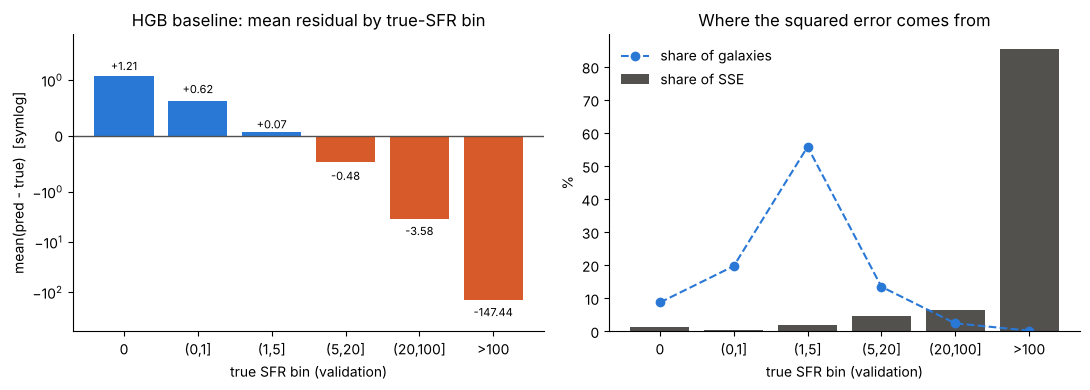

In [12]:
# 그림: 기준선이 어디서 틀리나 — 참 SFR 구간별 평균 잔차(왼쪽)와 SSE 비중(오른쪽). 그림 글자는 영어.
labels = ["0", "(0,1]", "(1,5]", "(5,20]", "(20,100]", ">100"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.bar(labels, baseline_bins["mean_residual"], color=["#2a78d6" if v > 0 else "#d65a2a" for v in baseline_bins["mean_residual"]])
ax.axhline(0, color="#52514e", lw=1)
ax.set_yscale("symlog", linthresh=1)
ax.set_ylim(-600, 8)
ax.set_xlabel("true SFR bin (validation)")
ax.set_ylabel("mean(pred - true)  [symlog]")
ax.set_title("HGB baseline: mean residual by true-SFR bin")
for k, v in enumerate(baseline_bins["mean_residual"]):
    ax.text(k, v * (1.15 if v > 0 else 1.25), f"{v:+.2f}", ha="center", va="bottom" if v > 0 else "top", fontsize=8)
ax = axes[1]
ax.bar(labels, baseline_bins["SSE_share"] * 100, color="#52514e", label="share of SSE")
ax.plot(labels, baseline_bins["n_share"] * 100, "o--", color="#2a78d6", label="share of galaxies")
ax.set_xlabel("true SFR bin (validation)")
ax.set_ylabel("%")
ax.set_title("Where the squared error comes from")
ax.legend(frameon=False)
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**무엇을 보여 주나.** 기준선은 작은 SFR을 **과대**, 큰 SFR을 **과소**예측한다. 평균 잔차는 SFR = 0에서 +1.21, (0, 1]에서 +0.62, (20, 100]에서 −3.58, SFR > 100에서 −147.4다. 오른쪽 그림에서 은하의 0.15%(SFR > 100, 61개)가 SSE의 85.5%를 만든다.

**왜.** 제곱 손실 모델은 비슷한 피처를 가진 은하들의 평균 쪽으로 예측을 당긴다. 그래서 0 은하는 주변 양수 은하에 끌려 올라가고, 극단 은하는 내려간다. 트리는 학습에서 본 값의 범위 밖으로 외삽하지 못한다(val 예측 최대 175.6, 참 최대 884.1). 극단 은하는 수가 적고 13개 피처로 구별되지 않는다.

**모델에 주는 결정.** (1) 0 은하의 과대예측은 "0인가"를 따로 모델링해 줄일 수 있다(→ 7절 2단계 모델). (2) 꼬리 과소예측이 RMSE를 지배하므로, 타깃을 압축하는 처리(log1p)는 RMSE에서 불리할 것이라고 실행 전에 예상했다(→ 7절 실험 1). (3) 음수 예측이 19개 있으므로 0으로 자르는 처리를 넣는다. 참값이 0 이상이라 자르면 RMSE는 나빠질 수 없다.

### 6.1 Baseline Interpretation — **STUDENT RESPONSE**

**Response:**

- **과제의 난이도.** HGB 기준선은 val RMSE를 중앙값 기준선 12.345에서 **9.513**으로 22.9%만 줄였다(R² 0.388). 실제로 쓴 트리는 `max_iter` 150개가 아니라 **37개**다. 학습 데이터가 10,000개를 넘어 early stopping이 자동으로 켜졌기 때문이다. train RMSE 7.32와 val RMSE 9.51의 차이도 크다. 그래도 MAE는 1.30으로 보통 은하는 잘 맞힌다. 어려움은 평균적인 은하가 아니라 분포 양 끝에 있다.
- **실패 위치 1 — 긴 꼬리.** Top 10% 줄의 RMSE는 29.40, R²는 0.249다. SFR > 100인 val 은하 61개를 평균 −147.4만큼 과소예측하고, 이 61개가 SSE의 **85.5%**다. 이들을 완벽히 맞히면 RMSE가 약 3.6까지 내려간다. 예측 최대값은 175.6인데 참 최대값은 884.1이다. 트리는 학습 범위 밖으로 외삽하지 못하고, 13개 피처로는 극단 은하를 구별하기 어렵다. 따라서 **공식 점수는 극소수의 꼬리 은하가 정하며**, 모델 간 차이 0.1~0.3은 이 꼬리 때문에 생기는 표본 잡음(부트스트랩 SE 1.37) 안에 있다.
- **실패 위치 2 — 꺼진 은하.** 참값이 0인 은하 3,610개를 평균 **+1.21**로 예측한다(SFR = 0 RMSE 3.55). 제곱 손실이 같은 피처의 양수 은하 쪽으로 예측을 당기기 때문이다. 이 regime은 SSE의 1.2%라 All RMSE에는 거의 영향이 없다. 그러나 "꺼짐"을 물리적으로 다르게 다루지 못한다는 뜻이다. 예측에는 음수도 19개 있다(최소 −6.54).
- **그래서 7절에서 시험할 것.** (1) 0을 따로 다루는 2단계 모델. (2) 타깃 처리(log1p, Poisson)가 꼬리와 0에 주는 영향을 같은 설정에서 비교. (3) 차이는 구간으로 판정.

## 7. Preliminary Model / Proposed Method — **STUDENT WORK**

Implement at least one preliminary approach or provide a working prototype of the method you plan to develop. You are free to use conventional ML, neural networks, graph-based methods, ensembles, two-stage models, or other justified approaches.

#### 7절 실험 1 — 같은 HGB, 손실·타깃 처리만 바꾸기 (EDA 3 → "원래 척도 / log1p / 0 분리를 같은 선형 RMSE로 비교")

In [13]:
# 7절 실험 1 (조장): 같은 HGB 설정(HGB)에서 손실·타깃 처리만 바꾼다 — 변인 통제. 평가는 공통 분할 val + evaluate_sfr.
preds, models = {}, {}

# (a) 제곱 손실 = 기준선과 같은 모델 (맞히려는 양: E[SFR | x], 공식 지표 RMSE와 같은 양)
models["(a) squared"] = HistGradientBoostingRegressor(**HGB).fit(X_train, y_train)
preds["(a) squared"] = models["(a) squared"].predict(X_val)

# (b) log1p로 학습 후 expm1로 되돌림 (맞히려는 양: exp(E[log(1+SFR)|x]) - 1 ≈ 조건부 중앙값 쪽)
models["(b) log1p"] = HistGradientBoostingRegressor(**HGB).fit(X_train, np.log1p(y_train))
z_hat_val = models["(b) log1p"].predict(X_val)
preds["(b) log1p"] = np.expm1(z_hat_val)

# (b') (b) + Duan smearing 되돌림 보정: 1 + y = exp(z), 훈련 로그 잔차의 exp 평균을 곱한다
resid_log = np.log1p(y_train) - models["(b) log1p"].predict(X_train)
SMEAR = float(np.mean(np.exp(resid_log)))
preds["(b') log1p + smearing"] = np.exp(z_hat_val) * SMEAR - 1

# (c) Poisson 손실 (log 링크, 예측은 항상 양수)
models["(c) poisson"] = HistGradientBoostingRegressor(loss="poisson", **HGB).fit(X_train, y_train)
preds["(c) poisson"] = models["(c) poisson"].predict(X_val)

# (c') Poisson에 트리를 더 준다 / (a') 공정 비교를 위해 제곱 손실에도 같은 큰 설정
BIG = dict(learning_rate=0.05, max_iter=600, max_leaf_nodes=63, random_state=RANDOM_SEED)
models["(c') poisson big"] = HistGradientBoostingRegressor(loss="poisson", **BIG).fit(X_train, y_train)
preds["(c') poisson big"] = models["(c') poisson big"].predict(X_val)
models["(a') squared big"] = HistGradientBoostingRegressor(**BIG).fit(X_train, y_train)
preds["(a') squared big"] = models["(a') squared big"].predict(X_val)

loss_table = pd.concat([evaluate_sfr(y_val, p, k) for k, p in preds.items()], ignore_index=True)
display(loss_table.round(3))

print(f"smearing 계수 {SMEAR:.4f} | 로그 잔차 분산 {resid_log.var():.4f} → 정규 가정 보정 exp(σ²/2) = {np.exp(resid_log.var() / 2):.4f}")
print(f"참 평균(val) {y_val.mean():.3f}")
for k, p in preds.items():
    print(f"  {k:24s} 예측 평균 {p.mean():6.3f} | 최소 {p.min():7.3f} | 최대 {p.max():7.1f} | n_iter_ {models.get(k, models['(b) log1p']).n_iter_}")

,Model,Regime,N,MAE,RMSE,R2
0,(a) squared,All,41688,1.296,9.513,0.388
1,(a) squared,SFR = 0,3610,1.214,3.551,0.000
2,(a) squared,SFR > 0,38078,1.303,9.894,0.390
3,(a) squared,Top 10% SFR,4169,6.583,29.404,0.249
4,(b) log1p,All,41688,1.092,9.810,0.349
5,(b) log1p,SFR = 0,3610,0.264,0.964,0.000
6,(b) log1p,SFR > 0,38078,1.171,10.260,0.344
7,(b) log1p,Top 10% SFR,4169,6.412,30.886,0.171
8,(b') log1p + smearing,All,41688,1.096,9.785,0.353
9,(b') log1p + smearing,SFR = 0,3610,0.300,1.004,0.000


smearing 계수 1.0326 | 로그 잔차 분산 0.0585 → 정규 가정 보정 exp(σ²/2) = 1.0297
참 평균(val) 3.751
  (a) squared              예측 평균  3.654 | 최소  -6.544 | 최대   175.6 | n_iter_ 37
  (b) log1p                예측 평균  3.347 | 최소  -0.297 | 최대   126.3 | n_iter_ 150
  (b') log1p + smearing    예측 평균  3.489 | 최소  -0.274 | 최대   130.4 | n_iter_ 150
  (c) poisson              예측 평균  3.682 | 최소   0.017 | 최대   725.5 | n_iter_ 90
  (c') poisson big         예측 평균  3.603 | 최소   0.014 | 최대   270.6 | n_iter_ 136
  (a') squared big         예측 평균  3.651 | 최소 -10.874 | 최대   180.0 | n_iter_ 61


**결과(같은 설정, val).** All RMSE는 (a) 제곱 9.513 < (b) log1p 9.810 < (c) Poisson 11.379다. MAE와 SFR = 0 줄의 순서는 반대다. (b)가 MAE 1.092, SFR = 0 RMSE 0.964로 가장 좋다. **지표를 바꾸면 승자가 바뀐다.** 판정은 공식 지표인 RMSE로 한다.

**(b) log1p가 RMSE에서 지는 이유.** 로그 척도에서 제곱 손실은 E[log(1+Y)|x]를 맞힌다. Jensen 부등식에 따라 이것을 되돌린 값 exp(E[log(1+Y)|x]) − 1은 E[Y|x]보다 작다. 그래서 예측이 조건부 중앙값 쪽으로 가고 꼬리를 체계적으로 과소예측한다. 예측 평균은 3.347로 참 평균 3.751보다 10.8% 작고, Top 10% RMSE는 30.89다. train 잔차로 Duan smearing 보정(계수 1.033, 정규 가정 보정 1.030과 거의 같음)을 해도 예측 평균은 3.489에 그친다. RMSE는 9.785로 거의 그대로다. 보정 상수가 하나뿐이어서, 로그 잔차의 분산이 x에 따라 다르면(이분산) 꼬리의 편향을 다 고치지 못한다.

**(c) Poisson이 지는 이유.** Poisson deviance는 오차를 대략 (y − μ)²/μ로 잰다. 즉 큰 은하의 **절대** 오차를 RMSE보다 덜 벌한다. 또 log 링크에서는 예측이 곱셈으로 커지므로 꼬리까지 가는 데 트리가 많이 필요하다. 그런데 deviance 기준 early stopping은 90번째 트리에서 멈췄다. 트리를 더 주면(c′: 학습률 0.05, 잎 63, 실제 136개) 9.550으로 같은 큰 설정의 제곱 손실(a′, 9.537)과 같아진다. 즉 패배의 대부분은 최적화 부족이었다. Poisson은 예측이 항상 양수이고 SFR = 0 줄이 좋다(2.02 vs 3.04)는 장점이 있다.

**결정.** 공식 지표가 E[Y|x]를 요구하므로 타깃은 **원래 척도 + 제곱 손실**로 둔다. 0 regime 문제는 손실이 아니라 구조(2단계)로 다룬다.

#### 7절 실험 2 — 2단계(hurdle) 모델 = `FINAL_MODEL` (EDA 1·2 → "0인가"를 따로 배우기)

In [14]:
# 7절 (조장): 2단계(hurdle) 모델 — ŷ = P(SFR>0 | x) × E[SFR | SFR>0, x]
# 제곱오차를 최소화하는 예측은 E[SFR|x]이고, 총기대 법칙으로 E[SFR|x] = P(SFR>0|x)·E[SFR|SFR>0,x] (zero-inflated 모형의 (1-π)μ와 같은 식).
# 따라서 "자르기"(P>0.5면 E, 아니면 0)가 아니라 "곱"을 쓴다.
from sklearn.ensemble import HistGradientBoostingClassifier


class TwoStageSFR:
    """분류기 P(y>0|x)와 양수 은하만으로 학습한 회귀기 E[y|y>0,x]를 곱하는 모델."""

    def __init__(self, hgb_params, reg_loss="squared_error", clip_zero=True):
        self.hgb_params = hgb_params
        self.reg_loss = reg_loss
        self.clip_zero = clip_zero

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        pos = y > 0
        self.clf_ = HistGradientBoostingClassifier(**self.hgb_params).fit(X, pos.astype(int))
        self.reg_ = HistGradientBoostingRegressor(loss=self.reg_loss, **self.hgb_params).fit(X[pos], y[pos])
        return self

    def predict_proba_positive(self, X):
        return self.clf_.predict_proba(X)[:, 1]

    def predict_positive_mean(self, X):
        e = self.reg_.predict(X)
        return np.clip(e, 0, None) if self.clip_zero else e  # E[y|y>0] >= 0

    def predict(self, X):
        return self.predict_proba_positive(X) * self.predict_positive_mean(X)


FINAL_MODEL = TwoStageSFR(hgb_params=HGB)  # 두 단계 모두 기준선과 같은 HGB 설정 (변인 통제)

_t0 = time.time()
FINAL_MODEL.fit(X_train, y_train)
FINAL_TRAIN_SECONDS = time.time() - _t0
VAL_PREDICTIONS = FINAL_MODEL.predict(X_val)

assert len(VAL_PREDICTIONS) == len(y_val)
assert np.isfinite(VAL_PREDICTIONS).all()
print(f"Training time: {FINAL_TRAIN_SECONDS:.1f} s")
print(f"n_iter_ — 분류기 {FINAL_MODEL.clf_.n_iter_}, 양수 회귀기 {FINAL_MODEL.reg_.n_iter_}")

Training time: 1.5 s
n_iter_ — 분류기 150, 양수 회귀기 38


In [15]:
# 2단계 모델 진단: 곱 vs 자르기, 양수 회귀기 손실(Poisson) 변형, 분류기 품질·보정
from sklearn.metrics import roc_auc_score, log_loss

p_val = FINAL_MODEL.predict_proba_positive(X_val)
e_val = FINAL_MODEL.predict_positive_mean(X_val)
preds["(d) two-stage P x E"] = VAL_PREDICTIONS
preds["(d-hard) 1[P>0.5] x E"] = np.where(p_val > 0.5, e_val, 0.0)
preds["(d, no clip)"] = p_val * FINAL_MODEL.reg_.predict(X_val)
model_dp = TwoStageSFR(hgb_params=HGB, reg_loss="poisson").fit(X_train, y_train)
preds["(d') two-stage, Poisson reg"] = model_dp.predict(X_val)

keys = ["(a) squared", "(d) two-stage P x E", "(d, no clip)", "(d-hard) 1[P>0.5] x E", "(d') two-stage, Poisson reg"]
display(pd.concat([evaluate_sfr(y_val, preds[k], k) for k in keys], ignore_index=True).round(3))

yv_pos = (y_val.to_numpy() > 0).astype(int)
print(f"분류기 AUC {roc_auc_score(yv_pos, p_val):.4f} | log loss {log_loss(yv_pos, p_val):.4f} "
      f"| 0.1 < p < 0.9인 은하 비율 {((p_val > 0.1) & (p_val < 0.9)).mean():.1%}")
print(f"(d) 예측 평균 {VAL_PREDICTIONS.mean():.3f} vs 참 평균 {y_val.mean():.3f} | 음수 예측 {(VAL_PREDICTIONS < 0).sum()}개")

calib = (pd.DataFrame({"p": p_val, "pos": yv_pos})
         .groupby(pd.cut(p_val, [0, 0.1, 0.3, 0.5, 0.7, 0.9, 0.99, 1.0]), observed=True)
         .agg(n=("pos", "size"), mean_p=("p", "mean"), frac_positive=("pos", "mean")))
print("분류기 보정표 (mean_p ≈ frac_positive이면 확률이 잘 맞는다):")
display(calib.round(3))

,Model,Regime,N,MAE,RMSE,R2
0,(a) squared,All,41688,1.296,9.513,0.388
1,(a) squared,SFR = 0,3610,1.214,3.551,0.000
2,(a) squared,SFR > 0,38078,1.303,9.894,0.390
3,(a) squared,Top 10% SFR,4169,6.583,29.404,0.249
4,(d) two-stage P x E,All,41688,1.240,9.434,0.398
5,(d) two-stage P x E,SFR = 0,3610,0.554,2.913,0.000
6,(d) two-stage P x E,SFR > 0,38078,1.305,9.830,0.398
7,(d) two-stage P x E,Top 10% SFR,4169,6.561,29.149,0.262
8,"(d, no clip)",All,41688,1.241,9.443,0.397
9,"(d, no clip)",SFR = 0,3610,0.556,2.913,0.000


분류기 AUC 0.9945 | log loss 0.0507 | 0.1 < p < 0.9인 은하 비율 6.0%
(d) 예측 평균 3.648 vs 참 평균 3.751 | 음수 예측 0개
분류기 보정표 (mean_p ≈ frac_positive이면 확률이 잘 맞는다):


,n,mean_p,frac_positive
"(0.0, 0.1]",2256,0.039,0.035
"(0.1, 0.3]",984,0.177,0.174
"(0.3, 0.5]",388,0.392,0.371
"(0.5, 0.7]",348,0.602,0.632
"(0.7, 0.9]",761,0.825,0.820
"(0.9, 0.99]",3399,0.964,0.973
"(0.99, 1.0]",33552,0.999,0.999


**결과.** (d) P × E는 All RMSE **9.434**(기준선 9.513), SFR = 0 RMSE **2.913**(3.551), Top 10% 29.149(29.404), 음수 예측 0개다. "곱" 대신 "자르기"(d-hard: P > 0.5면 E, 아니면 0)를 쓰면 All 9.454에 SFR = 0 RMSE가 3.742로 나빠진다. 확실히 0이라고 판단한 은하는 0을 맞히지만, 틀린 은하에서 크게 틀리기 때문이다. 양수 회귀기에 Poisson 손실을 쓰면(d′) 10.373으로 나빠진다. 실험 1의 (c)와 같은 이유다.

**왜 곱인가, 왜 이득이 작은가.** 어떤 x에서 상수 c를 예측할 때 기대 제곱오차는 Var(Y|x) + (c − p·e)²다. 따라서 최적값은 c = p·e이고, 자르기는 (1−p)²e² 또는 p²e²만큼 손해를 본다. 분류기는 AUC 0.9945, log loss 0.0507이고 보정표에서 mean_p ≈ frac_positive로 **잘 보정**되어 있다. 하지만 val의 94%가 p < 0.1 또는 p > 0.9인 "확실한" 은하라서 곱과 자르기의 차이가 애매한 6%에서만 생긴다. 그래서 All RMSE 차이가 작다.

**참고.** 분류기는 `max_iter` 상한 150에 닿았다(`n_iter_` 150). log loss가 계속 조금씩 줄고 있다는 뜻이다. 양수 회귀기는 38개에서 멈췄다. 분류기 트리 수 조정은 최종 보고서 과제로 남긴다.

#### 7절 실험 3 — 모델 구조를 `X_train` 안 5-fold CV로도 비교 (선택은 train 안에서)

In [16]:
# 7절 실험 3 (조장): 주요 후보를 5절의 같은 5개 fold(X_train 안)에서도 비교 — val을 보지 않고 고를 수 있었는지 확인.
def fit_predict(kind, Xa, ya, Xb):
    if kind == "(a) squared":
        return HistGradientBoostingRegressor(**HGB).fit(Xa, ya).predict(Xb)
    if kind == "(b) log1p":
        return np.expm1(HistGradientBoostingRegressor(**HGB).fit(Xa, np.log1p(ya)).predict(Xb))
    if kind == "(c) poisson":
        return HistGradientBoostingRegressor(loss="poisson", **HGB).fit(Xa, ya).predict(Xb)
    if kind == "(d) two-stage P x E":
        return TwoStageSFR(hgb_params=HGB).fit(Xa, ya).predict(Xb)
    raise ValueError(kind)

cv_model_rows = []
for kind in ["(a) squared", "(b) log1p", "(c) poisson", "(d) two-stage P x E"]:
    f_all, f_zero, f_le100 = [], [], []
    for tr, te in FOLDS:
        p = fit_predict(kind, Xtr.iloc[tr], ytr.iloc[tr], Xtr.iloc[te])
        yt = ytr.iloc[te].to_numpy()
        f_all.append(rmse(yt, p)); f_zero.append(rmse(yt[yt == 0], p[yt == 0])); f_le100.append(rmse(yt[yt <= 100], p[yt <= 100]))
    cv_model_rows.append({"model": kind, "CV RMSE": np.mean(f_all), "fold SD": np.std(f_all, ddof=1),
                          "fold RMSE": [round(v, 2) for v in f_all],
                          "CV RMSE (SFR=0)": np.mean(f_zero), "CV RMSE (SFR<=100)": np.mean(f_le100)})
cv_models = pd.DataFrame(cv_model_rows)
fold_mat = np.array([r for r in cv_models["fold RMSE"]])
cv_models["(d)보다 나쁜 fold 수"] = [int((fold_mat[i] > fold_mat[3]).sum()) for i in range(len(fold_mat))]
display(cv_models.round(3))

,model,CV RMSE,fold SD,fold RMSE,CV RMSE (SFR=0),CV RMSE (SFR<=100),(d)보다 나쁜 fold 수
0,(a) squared,8.325,3.988,"[14.44, 10.32, 6.01, 5.4, 5.45]",2.722,4.075,1
1,(b) log1p,8.437,4.164,"[14.72, 10.73, 5.76, 5.42, 5.56]",1.194,2.635,2
2,(c) poisson,10.547,3.485,"[14.71, 10.75, 6.86, 13.15, 7.26]",1.884,5.376,5
3,(d) two-stage P x E,8.455,3.841,"[14.24, 10.57, 6.23, 5.55, 5.68]",1.889,3.972,0


**val을 보지 않았어도 같은 결론이었나.** train 안 CV에서도 순서는 val과 같다. (c) Poisson이 10.547로 가장 나쁘다. (a) 8.325, (b) 8.437, (d) 8.455는 fold SD(약 4) 안에서 구별되지 않는다. All RMSE로는 CV가 (d)를 고르지 않는다. (a)가 (d)보다 0.13 낮고, 5개 fold 중 4개에서 (d)가 조금 나쁘다. 반면 꼬리를 뺀 SFR ≤ 100(3.972 vs 4.075)과 SFR = 0(1.889 vs 2.722)에서는 (d)가 (a)보다 좋다. (b)는 이 두 줄에서 가장 좋지만 All에서는 뒤진다.

**결정에 주는 의미.** (d)를 고르는 근거는 "All RMSE가 더 낮아서"가 아니다. 근거는 (1) 공식 지표가 요구하는 E[Y|x]를 그대로 분해한 구조이고, (2) 꼬리가 아닌 영역(0, ≤ 100)에서 CV와 val 모두 일관되게 낫고, (3) All에서는 손해가 구별되지 않는다는 것이다. 7.1에 이대로 쓴다.

#### 7절 실험 4 — 기준선과의 차이에 쌍 부트스트랩 95% 구간 붙이기 + EDA 4가 제안한 BH 제외 비교

In [17]:
# 7절 실험 4 (조장): 기준선 대비 RMSE 차이의 쌍 부트스트랩 95% 구간 (같은 검증 행을 두 모델에 함께 재표집)
def paired_rmse_ci(pred_a, pred_b, y, B=1000, seed=RANDOM_SEED, chunk=100):
    """RMSE(b) - RMSE(a)의 점추정과 percentile 95% 구간. 재표집 단위 = 검증 은하 한 개."""
    y = np.asarray(y, float)
    ea, eb = (np.asarray(pred_a) - y) ** 2, (np.asarray(pred_b) - y) ** 2
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(B // chunk):
        idx = rng.integers(0, len(y), size=(chunk, len(y)), dtype=np.int32)
        diffs.append(np.sqrt(eb[idx].mean(axis=1)) - np.sqrt(ea[idx].mean(axis=1)))
    diffs = np.concatenate(diffs)
    return float(np.sqrt(eb.mean()) - np.sqrt(ea.mean())), float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))

# 기준선 RMSE 자체가 검증 표본에 따라 얼마나 흔들리나
_rng = np.random.default_rng(RANDOM_SEED)
_e = (baseline_pred - y_val.to_numpy()) ** 2
_boot = np.concatenate([np.sqrt(_e[_rng.integers(0, len(_e), size=(100, len(_e)), dtype=np.int32)].mean(axis=1)) for _ in range(10)])
print(f"기준선 val RMSE {np.sqrt(_e.mean()):.3f}의 부트스트랩: SE {_boot.std(ddof=1):.3f}, 95% [{np.percentile(_boot, 2.5):.2f}, {np.percentile(_boot, 97.5):.2f}]")

# EDA 4의 제안: BH 질량을 빼면 어떻게 되나 (+ 참고로 위치·속도 6열 제외). 기준선 설정 그대로 다시 학습.
POSVEL = [c for c in FINAL_FEATURES if c.startswith(("pos_", "vel_"))]
for name, drop in {"(abl) drop BH": ["log10_BH_mass"], "(abl) drop pos/vel (6)": POSVEL}.items():
    feats = [c for c in FINAL_FEATURES if c not in drop]
    preds[name] = HistGradientBoostingRegressor(**HGB).fit(X_train[feats], y_train).predict(X_val[feats])

ci_rows = []
for name, p in preds.items():
    if name in ["(a) squared", "(d, no clip)"]:
        continue
    d, lo, hi = paired_rmse_ci(baseline_pred, p, y_val)
    ci_rows.append({"model": name, "val RMSE": rmse(y_val, p), "ΔRMSE vs baseline": d, "95% CI low": lo, "95% CI high": hi,
                    "판정": "개선" if hi < 0 else ("악화" if lo > 0 else "동등(구간이 0 포함)")})
ci_table = pd.DataFrame(ci_rows)
display(ci_table.round(3))

기준선 val RMSE 9.513의 부트스트랩: SE 1.365, 95% [6.92, 12.31]


,model,val RMSE,ΔRMSE vs baseline,95% CI low,95% CI high,판정
0,(b) log1p,9.810,0.296,-0.113,0.730,동등(구간이 0 포함)
1,(b') log1p + smearing,9.785,0.271,-0.135,0.701,동등(구간이 0 포함)
2,(c) poisson,11.379,1.866,0.280,3.724,악화
3,(c') poisson big,9.550,0.037,-0.429,0.442,동등(구간이 0 포함)
4,(a') squared big,9.537,0.023,-0.129,0.141,동등(구간이 0 포함)
5,(d) two-stage P x E,9.434,-0.079,-0.348,0.184,동등(구간이 0 포함)
6,(d-hard) 1[P>0.5] x E,9.454,-0.059,-0.333,0.209,동등(구간이 0 포함)
7,"(d') two-stage, Poisson reg",10.373,0.860,0.147,1.767,악화
8,(abl) drop BH,9.958,0.445,0.191,0.751,악화
9,(abl) drop pos/vel (6),9.329,-0.184,-0.729,0.392,동등(구간이 0 포함)


**결과.** 기준선 대비 RMSE 차이의 95% 구간이 0을 포함하지 않는 것은 **악화** 셋뿐이다. (c) Poisson +1.87 [+0.28, +3.72], (d′) 2단계 + Poisson 회귀기 +0.86 [+0.15, +1.77], **BH 제외** +0.45 [+0.19, +0.75]. **(d) 2단계 모델은 −0.08 [−0.35, +0.18]로 기준선과 동등**하다. 나머지(log1p, smearing, Poisson big, squared big, 자르기, 위치·속도 제외)도 모두 동등이다.

**EDA와의 연결.** EDA 4는 "BH는 양수 SFR의 크기 예측 후보이며 BH 제외 비교로 확인한다"고 제안했다. BH 질량을 빼면 All RMSE가 확실히 나빠지고(구간이 0보다 큼), SFR = 0 줄도 3.55 → 4.13으로 나빠진다(아래 요약 표). **BH는 유지한다.** 위치·속도 6열은 빼도 나빠지지 않는다(−0.18, 구간이 0 포함, 경향은 오히려 좋아짐). 그러나 "빼서 개선했다"고 쓸 수는 없다. 피처 선택(4절)은 팀원과 상의해 최종 보고서에서 정한다.

**주의.** 이 구간은 같은 val 행을 재표집한 것이라 "이 val 표본에서의 차이"의 불확실성이다. 학습 데이터가 달라질 때의 변동은 포함하지 않는다.

#### 7절 실험 5 — 두 단계가 각각 어느 피처에 기대나 (EDA 1·2·4·5와 맞춰 보기)

,분류기: log loss 증가,분류기 SD,양수 회귀기: RMSE 증가,양수 회귀기 SD,분류기 순위,회귀기 순위
log10_overdensity_plus_1,0.5819,0.0041,-0.0324,0.0155,1,10
log10_halo_mass,0.0749,0.0015,0.0748,0.0020,2,5
log10_main_prog_stellar_mass,0.0216,0.0006,0.0260,0.0012,3,7
log10_mass_ratio,0.0150,0.0008,0.0573,0.0224,4,6
log10_main_prog_mass,0.0109,0.0005,0.7868,0.0092,5,2
log10_stellar_mass,0.0055,0.0003,3.2321,0.0378,6,1
pos_y,0.0049,0.0001,0.0185,0.0794,7,8
pos_x,0.0047,0.0001,0.0860,0.0492,8,4
pos_z,0.0032,0.0001,-0.1000,0.0995,9,12
log10_BH_mass,0.0018,0.0001,0.1623,0.0581,10,3


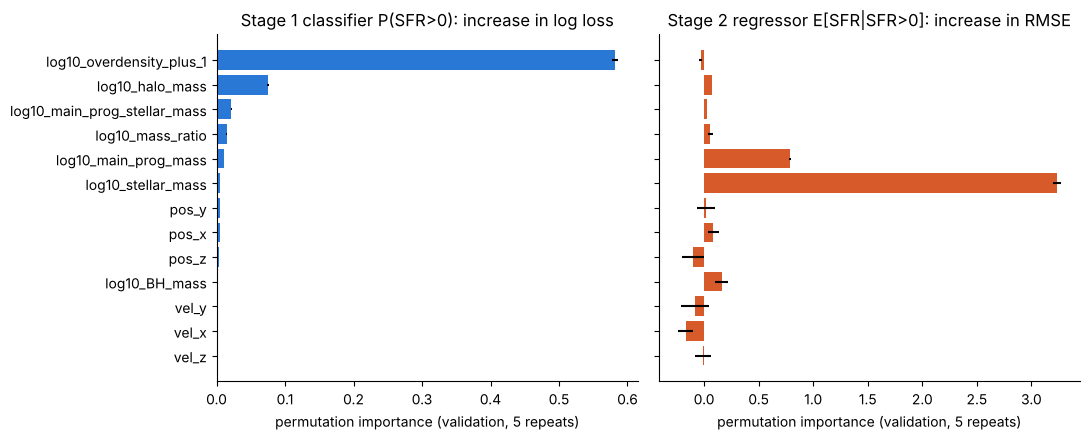

In [18]:
# 7절 실험 5 (조장): 2단계 모델의 두 조각이 각각 어떤 피처에 기대는지 — permutation importance (검증 데이터, 5회 반복)
# 해석용이다(모델 선택에 쓰지 않음). 분류기는 log loss 증가, 양수 회귀기는 양수 은하에서의 RMSE 증가로 잰다.
from sklearn.inspection import permutation_importance

imp_clf = permutation_importance(FINAL_MODEL.clf_, X_val, yv_pos, scoring="neg_log_loss",
                                 n_repeats=5, random_state=RANDOM_SEED, n_jobs=-1)
pos_mask = y_val.to_numpy() > 0
imp_reg = permutation_importance(FINAL_MODEL.reg_, X_val[pos_mask], y_val[pos_mask], scoring="neg_root_mean_squared_error",
                                 n_repeats=5, random_state=RANDOM_SEED, n_jobs=-1)
importance = pd.DataFrame({
    "분류기: log loss 증가": imp_clf.importances_mean,
    "분류기 SD": imp_clf.importances_std,
    "양수 회귀기: RMSE 증가": imp_reg.importances_mean,
    "양수 회귀기 SD": imp_reg.importances_std,
}, index=FINAL_FEATURES)
importance["분류기 순위"] = importance["분류기: log loss 증가"].rank(ascending=False).astype(int)
importance["회귀기 순위"] = importance["양수 회귀기: RMSE 증가"].rank(ascending=False).astype(int)
display(importance.sort_values("분류기: log loss 증가", ascending=False).round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
order = importance.sort_values("분류기: log loss 증가").index
axes[0].barh(order, importance.loc[order, "분류기: log loss 증가"], xerr=importance.loc[order, "분류기 SD"], color="#2a78d6")
axes[0].set_title("Stage 1 classifier P(SFR>0): increase in log loss")
axes[1].barh(order, importance.loc[order, "양수 회귀기: RMSE 증가"], xerr=importance.loc[order, "양수 회귀기 SD"], color="#d65a2a")
axes[1].set_title("Stage 2 regressor E[SFR|SFR>0]: increase in RMSE")
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
    a.set_xlabel("permutation importance (validation, 5 repeats)")
plt.tight_layout()
plt.show()

**무엇을 보여 주나.** 두 단계가 **서로 다른 피처**에 기댄다.
- **분류기(꺼졌나)**: 주변 밀도 `log10_overdensity_plus_1`이 압도적이다. 섞으면 log loss가 0.58 늘어나며, 2위인 헤일로 질량(0.075)의 약 8배다.
- **양수 회귀기(얼마나 만드나)**: 항성 질량(섞으면 RMSE +3.23)과 전구체 헤일로 질량(+0.79)이 주로 쓰이고, BH 질량(+0.16)이 그다음이다. 주변 밀도는 회귀기에서는 0(−0.03 ± 0.02)이다.

**EDA와 맞춰 보기.** EDA 1·2의 "밀도는 SFR = 0과 강하게 연관"이 모델에서도 그대로 나타난다. 그리고 밀도는 "0인가"에만 쓰이고 "얼마나"에는 쓰이지 않는다. EDA 4의 "BH는 0 여부보다 양수 SFR의 크기와 관련"도 같은 방향이다(분류기 10위, 회귀기 3위). EDA 5의 병합 지표 `log10_mass_ratio`는 회귀기에서 작다(+0.06). 병합 은하가 몰려 있는 극단 SFR을 회귀기가 어차피 맞히지 못하기 때문일 수 있다(추정). 위치·속도 6열은 두 단계 모두 거의 0이고, 표준편차보다 작거나 음수다.

**한계.** permutation importance는 "학습된 모델이 그 열에 얼마나 기대나"를 재는 것이지 인과가 아니다. 상관된 질량 피처끼리는 중요도를 나눠 가질 수 있다(예: 항성 질량과 전구체 질량). 해석은 최종 보고서 12절에서 넓힌다.

#### 7절 요약 표 (7.1에 옮길 표)

In [19]:
# 7.1에 옮길 요약 표: 공식 지표(All RMSE) + 구간별 지표 + 기준선 대비 구간
order = ["(a) squared", "(b) log1p", "(b') log1p + smearing", "(c) poisson", "(c') poisson big", "(a') squared big",
         "(d) two-stage P x E", "(d-hard) 1[P>0.5] x E", "(d') two-stage, Poisson reg", "(abl) drop BH", "(abl) drop pos/vel (6)"]
rows = []
for k in order:
    t = evaluate_sfr(y_val, preds[k], k).set_index("Regime")
    rows.append({"model": k, "All RMSE": t.loc["All", "RMSE"], "All MAE": t.loc["All", "MAE"], "All R2": t.loc["All", "R2"],
                 "SFR=0 RMSE": t.loc["SFR = 0", "RMSE"], "SFR>0 RMSE": t.loc["SFR > 0", "RMSE"],
                 "Top10% RMSE": t.loc["Top 10% SFR", "RMSE"], "pred mean": preds[k].mean()})
summary = pd.DataFrame(rows).merge(ci_table[["model", "ΔRMSE vs baseline", "95% CI low", "95% CI high", "판정"]], on="model", how="left")
display(summary.round(3))

,model,All RMSE,All MAE,All R2,SFR=0 RMSE,SFR>0 RMSE,Top10% RMSE,pred mean,ΔRMSE vs baseline,95% CI low,95% CI high,판정
0,(a) squared,9.513,1.296,0.388,3.551,9.894,29.404,3.654,NaN,NaN,NaN,NaN
1,(b) log1p,9.810,1.092,0.349,0.964,10.260,30.886,3.347,0.296,-0.113,0.730,동등(구간이 0 포함)
2,(b') log1p + smearing,9.785,1.096,0.353,1.004,10.234,30.799,3.489,0.271,-0.135,0.701,동등(구간이 0 포함)
3,(c) poisson,11.379,1.225,0.125,2.406,11.883,32.078,3.682,1.866,0.280,3.724,악화
4,(c') poisson big,9.550,1.131,0.383,2.021,9.974,29.487,3.603,0.037,-0.429,0.442,동등(구간이 0 포함)
5,(a') squared big,9.537,1.231,0.385,3.035,9.935,29.576,3.651,0.023,-0.129,0.141,동등(구간이 0 포함)
6,(d) two-stage P x E,9.434,1.240,0.398,2.913,9.830,29.149,3.648,-0.079,-0.348,0.184,동등(구간이 0 포함)
7,(d-hard) 1[P>0.5] x E,9.454,1.232,0.396,3.742,9.825,29.117,3.647,-0.059,-0.333,0.209,동등(구간이 0 포함)
8,"(d') two-stage, Poisson reg",10.373,1.174,0.273,2.669,10.823,31.604,3.641,0.860,0.147,1.767,악화
9,(abl) drop BH,9.958,1.566,0.330,4.131,10.342,30.218,3.676,0.445,0.191,0.751,악화


### 7.1 Method Description — **STUDENT RESPONSE**

**Model / method:** 2단계(hurdle) 모델 `TwoStageSFR`. 예측은 ŷ(x) = p̂(x) · ê(x)다. 여기서 p̂(x) = P(SFR > 0 | x)는 HGB 분류기, ê(x) = E[SFR | SFR > 0, x]는 **양수 은하만으로** 학습한 HGB 회귀기(제곱 손실)다. 총기대 법칙으로 E[SFR|x] = P(SFR>0|x)·E[SFR|SFR>0,x]이므로, 이 곱은 zero-inflated 모형의 E[Y] = (1−π)μ와 같은 구조다. "P > 0.5로 자르기"가 아니라 곱을 쓴다.

같은 HGB 설정으로 비교한 후보는 다음과 같다(val, 기준선 대비 차이와 쌍 부트스트랩 95% 구간).

| 모델 | 타깃 처리 | All RMSE | All MAE | SFR = 0 RMSE | Top 10% RMSE | ΔRMSE [95% 구간] | 판정 |
|---|---|---:|---:|---:|---:|---|---|
| (a) HGB 기준선 | 원래 척도, 제곱 | 9.513 | 1.296 | 3.551 | 29.40 | — | — |
| (b) log1p → expm1 | log1p | 9.810 | **1.092** | **0.964** | 30.89 | +0.30 [−0.11, +0.73] | 동등 |
| (b′) (b) + smearing | log1p, 보정 1.033 | 9.785 | 1.096 | 1.004 | 30.80 | +0.27 [−0.14, +0.70] | 동등 |
| (c) Poisson 손실 | log 링크 | 11.379 | 1.225 | 2.406 | 32.08 | +1.87 [+0.28, +3.72] | **악화** |
| (c′) Poisson, 트리 600·잎 63 | log 링크 | 9.550 | 1.131 | 2.021 | 29.49 | +0.04 [−0.43, +0.44] | 동등 |
| **(d) 2단계 P × E (채택)** | 원래 척도, 제곱 | **9.434** | 1.240 | 2.913 | 29.15 | −0.08 [−0.35, +0.18] | 동등 |
| (d-hard) 1[P > 0.5] × E | 원래 척도, 제곱 | 9.454 | 1.232 | 3.742 | 29.12 | −0.06 [−0.33, +0.21] | 동등 |
| (d′) 2단계, 회귀기 Poisson | log 링크 | 10.373 | 1.174 | 2.669 | 31.60 | +0.86 [+0.15, +1.77] | **악화** |

**Why you chose it:**
1. **지표와 같은 양을 겨냥한다.** 공식 지표 RMSE를 최소화하는 예측은 E[SFR|x]이고, (d)는 이것을 "꺼졌을 확률"과 "꺼지지 않았을 때의 SFR"로 정확히 분해한다. log1p(조건부 중앙값 쪽, Jensen에 의한 과소예측)와 Poisson(상대 오차 1/μ 가중)은 다른 양이나 다른 가중을 최소화해서 RMSE에서 뒤지거나 비긴다.
2. **EDA 근거.** EDA 1·2에서 SFR = 0은 주변 밀도와 강하게 연관된 별도의 과정으로 보였다. 2단계 모델의 분류기도 실제로 밀도에 압도적으로 기대고, 회귀기는 밀도를 거의 쓰지 않는다(permutation importance). 두 과정을 나눈 구조가 데이터와 맞는다.
3. **기준선의 실패를 줄인다.** 0 은하 과대예측(SFR = 0 RMSE 3.55 → 2.91; train 안 CV에서도 2.72 → 1.89)과 음수 예측(19개 → 0개)이 줄었다. All RMSE는 기준선과 **동등**하다(9.434 vs 9.513, 구간이 0 포함). 성능이 좋아서 고른 것이 아니다.

**Inputs / engineered features:** 템플릿 기본 13개 피처를 그대로 쓰고(`subhalo_id` 제외), 피처 공학은 하지 않았다. 손실·구조의 효과만 보려는 변인 통제다. 참고로 BH 질량을 빼면 확실히 나빠졌고(+0.45 [+0.19, +0.75]) 위치·속도 6열은 빼도 동등했다(−0.18 [−0.73, +0.39]). 피처 선택은 최종 보고서에서 정한다.

**Important hyperparameters:** 두 단계 모두 기준선과 같은 `HistGradientBoosting` 설정(learning_rate 0.08, max_leaf_nodes 31, max_iter 150, random_state 42)이다. early stopping이 자동으로 켜지므로(학습 데이터 > 10,000, 내부 검증 10%) 실제 트리 수는 분류기 **150개**(상한 도달), 양수 회귀기 **38개**다. train 안 5-fold CV로는 설정 간 차이(≤ 0.2)가 fold 간 흔들림(SD 약 4)보다 훨씬 작아 고를 근거가 없어서 기준선 값을 유지했다. 회귀기의 음수 예측은 0으로 자른다(E[SFR|SFR>0] ≥ 0). 학습 시간은 약 1.4초(CPU)다.

**Target transformation (if any):** 없음. 원래 척도에서 제곱 손실을 쓴다. log1p는 되돌림 편향 때문에 예측 평균이 10.8% 작아지고(3.35 vs 3.75), smearing 보정(×1.033)으로도 일부만 회복된다(3.49). Poisson 손실은 같은 설정에서는 최적화 부족과 1/μ 가중 때문에 RMSE 11.38이고, 트리를 충분히 주면 동등하다(9.55). 이 둘은 MAE·SFR = 0에서는 더 좋지만 공식 지표로 판정해 채택하지 않았다.

**Current limitations:**
1. **All RMSE 개선을 주장할 수 없다.** 기준선과의 차이 −0.08의 95% 구간이 [−0.35, +0.18]이다. train 안 CV의 All RMSE에서는 오히려 (a)가 0.13 낮다(구별 불가).
2. **꼬리는 그대로다.** Top 10% RMSE는 29.15(기준선 29.40)이고, SSE의 85%를 만드는 SFR > 100 은하는 여전히 크게 과소예측한다. 트리는 학습 범위 밖으로 외삽하지 못하고, 13개 피처로는 극단 은하를 구별하지 못한다.
3. **분해의 이득은 애매한 은하에서만 생긴다.** 분류기가 잘 보정되어 있지만(AUC 0.9945) val의 94%에서 p가 0.1 미만 또는 0.9 초과라서, 곱과 자르기의 차이는 나머지 6%에서만 생긴다.
4. **조정하지 않은 부분이 있다.** 분류기가 `max_iter` 상한에 닿았고, 두 단계 설정과 피처를 따로 조정하지 않았다. 단일 val 분할의 RMSE 자체가 표본에 따라 [6.9, 12.3]로 흔들린다.

## 8. Part I — Midterm Summary & Next-Step Plan — **REQUIRED**

Write approximately **200–300 words** summarizing:
1. the most important property of the dataset you discovered;
2. your baseline and preliminary performance;
3. what has and has not worked so far;
4. the main modeling hypothesis you will test before the final submission;
5. concrete next steps.

**Midterm summary:**  
...

### Midterm submission checklist
- [ ] Participant/team information is complete.
- [ ] Problem and objective are explained.
- [ ] Data quality and EDA are documented.
- [ ] Preprocessing choices are justified.
- [ ] Validation strategy is explained.
- [ ] Required baselines run successfully.
- [ ] Preliminary method/results are included.
- [ ] Midterm summary and next-step plan are complete.
- [ ] Notebook runs in order without relying on hidden state.

---
# Part II — Final Report

Continue from Part I in this **same notebook**. You may improve your earlier analysis, but do not delete Part I. Part II should document your final method, experiments, quantitative results, failure modes, astrophysical interpretation, and reproducibility information.

## 9. Final Modeling & Experiments — **STUDENT WORK**

Present the final modeling pipeline and the experiments that led to it. Your report should make clear **what changed from the midterm and why**. Do not include every failed trial; include experiments that materially informed the final design.

### 9.1 Changes Since Midterm — **STUDENT RESPONSE**

| Change | Motivation | Effect on validation performance / understanding |
|---|---|---|
|  |  |  |

**Final modeling rationale:** ...

### 9.2 Final Model Code

Place the complete code needed to train your final model and generate validation predictions below.

In [20]:
# STUDENT TODO — replace this example with your model.
# The starter simply copies the common baseline so the notebook remains runnable.
FINAL_MODEL = HistGradientBoostingRegressor(
    learning_rate=0.08,
    max_iter=150,
    max_leaf_nodes=31,
    random_state=RANDOM_SEED,
)

_t0 = time.time()
FINAL_MODEL.fit(X_train, y_train)
FINAL_TRAIN_SECONDS = time.time() - _t0
VAL_PREDICTIONS = FINAL_MODEL.predict(X_val)

assert len(VAL_PREDICTIONS) == len(y_val)
assert np.isfinite(VAL_PREDICTIONS).all()
print(f"Training time: {FINAL_TRAIN_SECONDS:.1f} s")

Training time: 0.4 s


### 9.3 Final Method Description — **STUDENT RESPONSE**

Describe the final algorithm/architecture, input features, preprocessing, target treatment, hyperparameters, training procedure, and any ensembling. Another student should be able to understand your method from this section without reverse-engineering the code.

**Response:**  
...

## 10. Results & Model Comparison — **REQUIRED**

Compare the baseline and the models that materially contributed to your final decision. Use the same validation data/metric when making direct comparisons.

In [21]:
# DO NOT MODIFY — standardized final evaluation
final_results = evaluate_sfr(y_val, VAL_PREDICTIONS, "Final model")
comparison = pd.concat([dummy_results, baseline_results, final_results], ignore_index=True)
display(comparison)

FINAL_SCORE = float(final_results.loc[final_results["Regime"] == "All", "RMSE"].iloc[0])
print("FINAL_SCORE (validation RMSE):", FINAL_SCORE)

,Model,Regime,N,MAE,RMSE,R2
0,Median baseline,All,41688,2.915509,12.345089,-0.030337
1,Median baseline,SFR = 0,3610,1.632815,1.632815,0.000000
2,Median baseline,SFR > 0,38078,3.037116,12.907243,-0.038139
3,Median baseline,Top 10% SFR,4169,18.678901,38.733401,-0.303030
4,HGB baseline,All,41688,1.295678,9.513444,0.388120
5,HGB baseline,SFR = 0,3610,1.214297,3.550815,0.000000
6,HGB baseline,SFR > 0,38078,1.303394,9.893973,0.390000
7,HGB baseline,Top 10% SFR,4169,6.582616,29.403706,0.249091
8,Final model,All,41688,1.295678,9.513444,0.388120
9,Final model,SFR = 0,3610,1.214297,3.550815,0.000000


FINAL_SCORE (validation RMSE): 9.513443932168478


### 10.1 Required Comparison Table — **STUDENT RESPONSE**

| Model | Key features / preprocessing | Target treatment | Validation MAE | Validation RMSE | R² | Notes |
|---|---|---|---:|---:|---:|---|
| Baseline |  |  |  |  |  |  |
| Model 1 |  |  |  |  |  |  |
| Model 2 |  |  |  |  |  |  |
| **Final model** |  |  |  |  |  |  |

### 10.2 Results Discussion
Which changes produced meaningful improvements? Are the improvements consistent across SFR regimes?

**Response:** ...

## 11. Error Analysis — **REQUIRED**

Go beyond a single aggregate score. Analyze where your final model succeeds and fails. At minimum, discuss **zero/quiescent**, **positive-SFR**, and **high-SFR** behavior. Additional physically motivated subsets are encouraged.

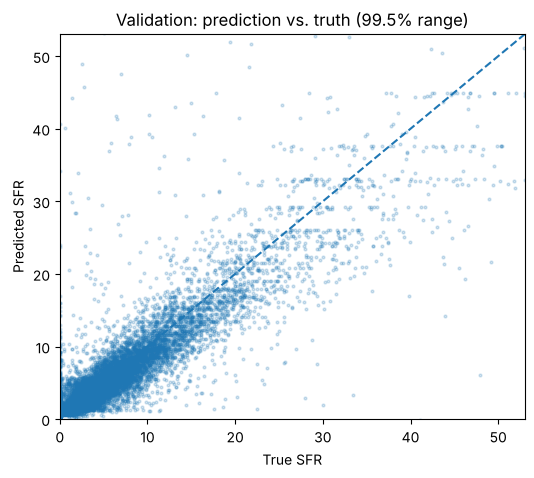

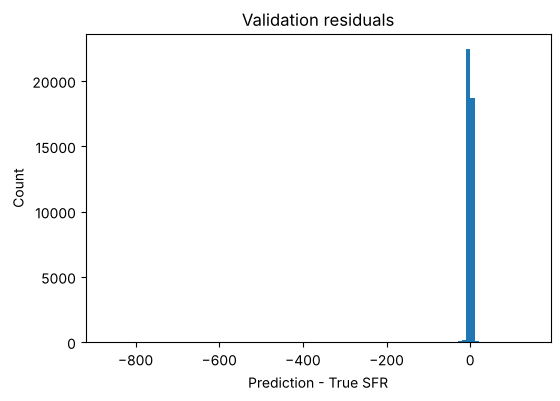

In [22]:
# Starter diagnostic plots — you may modify/add plots.
residual = np.asarray(VAL_PREDICTIONS) - y_val.to_numpy()

plt.figure(figsize=(6, 5))
plt.scatter(y_val, VAL_PREDICTIONS, s=4, alpha=0.2)
lims = [0, max(np.quantile(y_val, 0.995), np.quantile(VAL_PREDICTIONS, 0.995))]
plt.plot(lims, lims, "--")
plt.xlim(lims); plt.ylim(lims)
plt.xlabel("True SFR")
plt.ylabel("Predicted SFR")
plt.title("Validation: prediction vs. truth (99.5% range)")
plt.show()

plt.figure(figsize=(6, 4))
plt.hist(residual, bins=100)
plt.xlabel("Prediction - True SFR")
plt.ylabel("Count")
plt.title("Validation residuals")
plt.show()

### 11.1 Error-Analysis Discussion — **STUDENT RESPONSE**

**Zero / quiescent galaxies:** ...  
**Positive-SFR galaxies:** ...  
**High-SFR tail:** ...  
**Largest or most systematic failure mode:** ...  
**Likely explanation:** ...

## 12. Model Interpretation & Astrophysical Discussion — **REQUIRED**

Use an interpretation method appropriate for your model (for example, permutation importance, SHAP, ablation, partial dependence, learned graph/environmental analysis, or another justified method). The goal is not merely to rank features, but to connect the model behavior to the underlying astrophysics.

In [23]:
# STUDENT TODO — model interpretation.
# Example ideas: permutation importance, feature ablation, SHAP, partial dependence.
pass

### 12.1 Scientific Interpretation — **STUDENT RESPONSE**

Discuss:
- which information appears most important;
- whether the relationships are astrophysically plausible;
- what you learned about galaxy star formation or quenching;
- where interpretation is uncertain or model-dependent.

**Response:**  
...

## 13. Limitations & Conclusion — **REQUIRED**

### 13.1 Limitations
Identify at least **two substantive limitations** of your analysis, data, validation, or model.

1. ...
2. ...

### 13.2 Conclusion
In approximately **150–250 words**, state your final approach, main quantitative result, most important scientific/modeling insight, and what you would try next with more time or compute.

**Conclusion:**  
...

## 14. Final Model Card & Reproducibility — **REQUIRED**

Keep this concise and factual.

**Final model:** ...  
**Input features:** ...  
**Preprocessing / feature engineering:** ...  
**Target treatment:** ...  
**Validation strategy:** ...  
**Primary metric:** ...  
**Validation result:** ...  
**Random seed(s):** ...  
**Major hyperparameters:** ...  
**Approximate training time / hardware (if relevant):** ...  
**Biggest failure mode:** ...

## 15. Machine-Readable Results — **REQUIRED**

Keep the variable name `RESULTS`. This standardized block helps the instructors collect submission metadata and metrics consistently.

In [24]:
# STUDENT TODO — update model_name and notes; keep required keys.
_all = final_results.loc[final_results["Regime"] == "All"].iloc[0]
_zero = final_results.loc[final_results["Regime"] == "SFR = 0"].iloc[0]
_positive = final_results.loc[final_results["Regime"] == "SFR > 0"].iloc[0]

RESULTS = {
    "model_name": type(FINAL_MODEL).__name__,
    "features": list(FINAL_FEATURES),
    "n_features": len(FINAL_FEATURES),
    "random_seed": RANDOM_SEED,
    "validation_mae": float(_all["MAE"]),
    "validation_rmse": float(_all["RMSE"]),
    "validation_r2": float(_all["R2"]),
    "zero_sfr_mae": float(_zero["MAE"]),
    "positive_sfr_mae": float(_positive["MAE"]),
    "training_seconds": float(FINAL_TRAIN_SECONDS),
    "notes": "STUDENT TODO: one-line description of final approach",
}

print(json.dumps(RESULTS, indent=2))

{
  "model_name": "HistGradientBoostingRegressor",
  "features": [
    "log10_halo_mass",
    "log10_stellar_mass",
    "log10_BH_mass",
    "log10_main_prog_mass",
    "log10_main_prog_stellar_mass",
    "log10_mass_ratio",
    "log10_overdensity_plus_1",
    "pos_x",
    "pos_y",
    "pos_z",
    "vel_x",
    "vel_y",
    "vel_z"
  ],
  "n_features": 13,
  "random_seed": 42,
  "validation_mae": 1.2956784312907579,
  "validation_rmse": 9.513443932168478,
  "validation_r2": 0.38811991582605965,
  "zero_sfr_mae": 1.2142971218971765,
  "positive_sfr_mae": 1.303393818835031,
  "training_seconds": 0.3924243450164795,
  "notes": "STUDENT TODO: one-line description of final approach"
}


## 16. Final Submission Checklist

- [ ] Part I remains in the notebook and is complete.
- [ ] Changes since the midterm are documented.
- [ ] Final training and prediction code is included.
- [ ] Model comparison table is complete.
- [ ] Error analysis covers meaningful SFR regimes.
- [ ] Model interpretation is connected to astrophysics.
- [ ] Limitations and conclusion are complete.
- [ ] Final model card is complete.
- [ ] `RESULTS` executes successfully.
- [ ] All important figures have labels/captions and written interpretation.
- [ ] The notebook runs from top to bottom without hidden state or missing local variables.
- [ ] No unnecessary personal information is included.

**Submission reminder:** submit this completed notebook according to the official DataHub submission instructions.

**Required filename:** `DataHub_<ApplicationID>_mid/final.ipynb`

